| Nama | Nrp |
| --- | --- |
| Fahmi Alfayadh | 5054251015 |

<center>Tugas-4 Association Rule</center>

## Early Inspection & Data Cleaning

In [1]:
import polars as pl

df = pl.read_excel("Online Retail.xlsx")

In [2]:
df.head()

InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
i64,str,str,i64,datetime[ms],f64,i64,str
536365,"""85123A""","""WHITE HANGING HEART T-LIGHT HO…",6,2010-12-01 08:26:00,2.55,17850,"""United Kingdom"""
536365,"""71053""","""WHITE METAL LANTERN""",6,2010-12-01 08:26:00,3.39,17850,"""United Kingdom"""
536365,"""84406B""","""CREAM CUPID HEARTS COAT HANGER""",8,2010-12-01 08:26:00,2.75,17850,"""United Kingdom"""
536365,"""84029G""","""KNITTED UNION FLAG HOT WATER B…",6,2010-12-01 08:26:00,3.39,17850,"""United Kingdom"""
536365,"""84029E""","""RED WOOLLY HOTTIE WHITE HEART.""",6,2010-12-01 08:26:00,3.39,17850,"""United Kingdom"""


### Statistik Deskriptif

In [3]:
## statistik data

print(f"ukuran data: {df.shape}")
print(f"jumlah data null: {df.null_count()}")
print(f"jumlah data duplikat: {df.is_duplicated().sum()}")


ukuran data: (541909, 8)
jumlah data null: shape: (1, 8)
┌───────────┬───────────┬─────────────┬──────────┬─────────────┬───────────┬────────────┬─────────┐
│ InvoiceNo ┆ StockCode ┆ Description ┆ Quantity ┆ InvoiceDate ┆ UnitPrice ┆ CustomerID ┆ Country │
│ ---       ┆ ---       ┆ ---         ┆ ---      ┆ ---         ┆ ---       ┆ ---        ┆ ---     │
│ u32       ┆ u32       ┆ u32         ┆ u32      ┆ u32         ┆ u32       ┆ u32        ┆ u32     │
╞═══════════╪═══════════╪═════════════╪══════════╪═════════════╪═══════════╪════════════╪═════════╡
│ 9291      ┆ 0         ┆ 1454        ┆ 0        ┆ 0           ┆ 0         ┆ 135080     ┆ 0       │
└───────────┴───────────┴─────────────┴──────────┴─────────────┴───────────┴────────────┴─────────┘
jumlah data duplikat: 10147


### Null Value Handling:
Data beneran null | `Description` Kosong | `InvoiceNo` dibatalkan (C) 

In [4]:
import polars as pl

# Tambahkan .cast(pl.String) pada kolom InvoiceNo
jumlah_null = df.filter(
    pl.col('Description').is_null() | 
    pl.col('InvoiceNo').cast(pl.String).str.contains('C')
).height

print(f"Jumlah data deskripsi kosong atau invoice dibatalkan: {jumlah_null}")


Jumlah data deskripsi kosong atau invoice dibatalkan: 1454


### Drop Duplicate & Null

In [5]:
# drop duplicate & null

df = df.drop_nulls()
df = df.filter(
    ~pl.col('InvoiceNo').cast(pl.String).str.contains('C')
)

df = df.unique()
print(f"ukuran data setelah drop null: {df.shape}")
print(f"jumlah data null setelah drop null: {df.null_count()}")
print(f"jumlah data duplikat setelah drop null: {df.is_duplicated().sum()}")

ukuran data setelah drop null: (392732, 8)
jumlah data null setelah drop null: shape: (1, 8)
┌───────────┬───────────┬─────────────┬──────────┬─────────────┬───────────┬────────────┬─────────┐
│ InvoiceNo ┆ StockCode ┆ Description ┆ Quantity ┆ InvoiceDate ┆ UnitPrice ┆ CustomerID ┆ Country │
│ ---       ┆ ---       ┆ ---         ┆ ---      ┆ ---         ┆ ---       ┆ ---        ┆ ---     │
│ u32       ┆ u32       ┆ u32         ┆ u32      ┆ u32         ┆ u32       ┆ u32        ┆ u32     │
╞═══════════╪═══════════╪═════════════╪══════════╪═════════════╪═══════════╪════════════╪═════════╡
│ 0         ┆ 0         ┆ 0           ┆ 0        ┆ 0           ┆ 0         ┆ 0          ┆ 0       │
└───────────┴───────────┴─────────────┴──────────┴─────────────┴───────────┴────────────┴─────────┘
jumlah data duplikat setelah drop null: 0


## Reshape Dataset
Data dikelompokan berdasrakankan `InvoiceNo` untuk mendapatkan daftar produk yang dibeli oleh setiap pembelian.

In [6]:
df_reshaped = df.group_by("InvoiceNo").agg(
    pl.col("Description").alias("Products")
)

df_reshaped.head()

InvoiceNo,Products
i64,list[str]
563913,"[""WOOD BLACK BOARD ANT WHITE FINISH"", ""JUMBO BAG RED RETROSPOT"", … ""CARRIAGE""]"
567721,"[""PHARMACIE FIRST AID TIN"", ""WOODLAND MINI BACKPACK"", … ""SET OF 16 VINTAGE BLACK CUTLERY""]"
566816,"[""DOORMAT SPOTTY HOME SWEET HOME"", ""LUNCH BAG DOLLY GIRL DESIGN"", … ""CHERUB HEART DECORATION GOLD""]"
581485,"[""FAMILY PHOTO FRAME CORNICE"", ""ASSORTED COLOUR MINI CASES"", ""BAKING SET SPACEBOY DESIGN""]"
556845,"[""PACK OF 72 RETROSPOT CAKE CASES"", ""RECYCLED ACAPULCO MAT LAVENDER"", … ""SPACEBOY GIFT WRAP""]"


In [7]:
## sekarang drop column CustomerID karena tidak dibutuhkan lagi

df_reshaped = df_reshaped.drop("InvoiceNo")

In [8]:
## cek jumlah item unik di kolom Products

jumlah_item_unik = df_reshaped.select(
	pl.col("Products").explode().n_unique()
).item()

print(f"Jumlah item unik: {jumlah_item_unik}")

Jumlah item unik: 3877


## FP Growth

### modelling

In [9]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

# Ubah Polars Series menjadi Python List of Lists
transactions = df_reshaped['Products'].to_list()

# Preprocessing
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions) 

df_encoded = pd.DataFrame(te_ary, columns=te.columns_)


frequent_itemsets = fpgrowth(df_encoded, min_support=0.04, use_colnames=True)

# 3. Tampilkan itemsets yang sering muncul
print("Frequent Itemsets:")
print(frequent_itemsets)

# 4. Generate Aturan Asosiasi
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)

# Tampilkan hasil aturan asosiasi
if not rules.empty:
    print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])
else:
    print("Tidak ditemukan aturan yang memenuhi syarat min_support atau min_threshold.")


Frequent Itemsets:
     support                                          itemsets
0   0.086319              frozenset({JUMBO BAG RED RETROSPOT})
1   0.047421             frozenset({JAM MAKING SET WITH JARS})
2   0.041649               frozenset({JUMBO BAG VINTAGE LEAF})
3   0.106334   frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
4   0.091929             frozenset({REGENCY CAKESTAND 3 TIER})
5   0.055514      frozenset({PACK OF 72 RETROSPOT CAKE CASES})
6   0.054111                       frozenset({SPOTTY BUNTING})
7   0.044400     frozenset({RETROSPOT TEA SET CERAMIC 11 PC })
8   0.041163  frozenset({SET/5 RED RETROSPOT LID GLASS BOWLS})
9   0.074180        frozenset({ASSORTED COLOUR BIRD ORNAMENT})
10  0.069486              frozenset({LUNCH BAG RED RETROSPOT})
11  0.053302           frozenset({LUNCH BAG SPACEBOY DESIGN })
12  0.074450                        frozenset({PARTY BUNTING})
13  0.056754              frozenset({LUNCH BAG  BLACK SKULL.})
14  0.040785    frozenset({GARDENERS

### Evaluation

In [10]:
# 1. Sort rules by Lift and Confidence
sorted_rules = rules.sort_values(by=['lift', 'confidence'], ascending=False)

# 2. Filter high-quality rules
strong_rules = sorted_rules[sorted_rules['lift'] > 1]

# 3. Display evaluation metrics
print(f"Total FP-Growth rules found: {len(rules)}")
print(f"Strong rules (Lift > 1): {len(strong_rules)}\n")
print(strong_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']].head(10))


Total FP-Growth rules found: 0
Strong rules (Lift > 1): 0

Empty DataFrame
Columns: [antecedents, consequents, support, confidence, lift, leverage, conviction]
Index: []


In [11]:
import matplotlib.pyplot as plt


1
2
3
Min Support: 0.02, Total Rules: 20
2
3
Min Support: 0.03, Total Rules: 0
2
3
Min Support: 0.04, Total Rules: 0
2
3
Min Support: 0.05, Total Rules: 0


Text(0, 0.5, 'Total Rules')

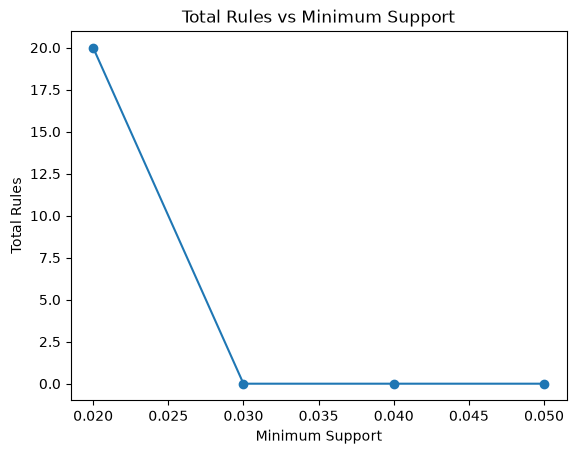

In [12]:
### buat grafik total rules berdasarkan support_minimum
n_rule = []
print("1")
for min_support in [0.02, 0.03, 0.04, 0.05]:
    print("2")
    frequent_itemsets = fpgrowth(df_encoded, min_support=min_support, use_colnames=True)
    print("3")
    rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)
    print(f"Min Support: {min_support}, Total Rules: {len(rules)}")
    n_rule.append(len(rules))

plt.Figure(figsize=(10, 6))
plt.plot([0.02, 0.03, 0.04, 0.05], n_rule, marker='o')
plt.title('Total Rules vs Minimum Support')
plt.xlabel('Minimum Support')
plt.ylabel('Total Rules')

    

## Apriori

### Modelling   

In [13]:
import polars as pl
import pandas as pd

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules




# ============================================================
# 3. FREQUENT ITEMSET MINING (APRIORI)
# ============================================================

frequent_itemsets = apriori(
    df_encoded,

    min_support=0.02,
    # Minimum proporsi transaksi yang mengandung itemset

    use_colnames=True,
    # Menggunakan nama produk, bukan indeks kolom

    max_len=None,
    # Maksimum jumlah item dalam satu itemset

    verbose=0,
    # Menampilkan progress proses mining

    low_memory=False
    # Menggunakan algoritma yang lebih cepat,
    # tetapi membutuhkan lebih banyak memory
)


# ============================================================
# 4. ASSOCIATION RULE GENERATION
# ============================================================

rules = association_rules(
    frequent_itemsets,

    num_itemsets=len(df_encoded),
    # Jumlah transaksi dalam dataset

    metric="confidence",
    # Metrik yang digunakan untuk filtering rules

    min_threshold=0.6,
    # Minimum confidence sebesar 60%

    support_only=False
    # Menghitung seluruh metrik association rules
)


# ============================================================
# 5. OUTPUT
# ============================================================

result = rules[
    [
        "antecedents",
        "consequents",
        "antecedent support",
        "consequent support",
        "support",
        "confidence",
        "lift",
        "leverage",
        "conviction"
    ]
].sort_values(
    by="lift",
    ascending=False
)

print(result)

                                          antecedents  \
19        frozenset({PINK REGENCY TEACUP AND SAUCER})   
16  frozenset({ROSES REGENCY TEACUP AND SAUCER , G...   
17  frozenset({ROSES REGENCY TEACUP AND SAUCER , P...   
7        frozenset({GREEN REGENCY TEACUP AND SAUCER})   
8         frozenset({PINK REGENCY TEACUP AND SAUCER})   
18  frozenset({GREEN REGENCY TEACUP AND SAUCER, PI...   
14        frozenset({PINK REGENCY TEACUP AND SAUCER})   
9       frozenset({ROSES REGENCY TEACUP AND SAUCER })   
10       frozenset({GREEN REGENCY TEACUP AND SAUCER})   
4                   frozenset({DOLLY GIRL LUNCH BOX})   
3                    frozenset({SPACEBOY LUNCH BOX })   
6      frozenset({GARDENERS KNEELING PAD KEEP CALM })   
5     frozenset({GARDENERS KNEELING PAD CUP OF TEA })   
0              frozenset({ALARM CLOCK BAKELIKE RED })   
1             frozenset({ALARM CLOCK BAKELIKE GREEN})   
2              frozenset({ALARM CLOCK BAKELIKE PINK})   
13     frozenset({PAPER CHAIN K

### Evaluation

In [14]:
# ============================================================
# 1. SORT ASSOCIATION RULES
# ============================================================

sorted_rules = rules.sort_values(
    by=["lift", "confidence", "support"],
    ascending=[False, False, False],
    na_position="last",
    ignore_index=True
)


# ============================================================
# 2. FILTER STRONG RULES
# ============================================================

strong_rules = sorted_rules[
    (sorted_rules["lift"] > 1.0) &
    (sorted_rules["confidence"] >= 0.6) &
    (sorted_rules["support"] >= 0.02)
].copy()


# ============================================================
# 3. ADDITIONAL METRICS
# ============================================================

# Number of items on each side of the rule
strong_rules["antecedent_len"] = strong_rules["antecedents"].apply(len)
strong_rules["consequent_len"] = strong_rules["consequents"].apply(len)

# Relative association improvement over independence baseline
strong_rules["lift_gain"] = strong_rules["lift"] - 1


# ============================================================
# 4. EVALUATION SUMMARY
# ============================================================

total_rules = len(rules)
selected_rules = len(strong_rules)

retention_rate = (
    selected_rules / total_rules * 100
    if total_rules > 0 else 0
)

print("=" * 55)
print("ASSOCIATION RULE EVALUATION")
print("=" * 55)

print(f"Total rules found    : {total_rules}")
print(f"Strong rules         : {selected_rules}")
print(f"Filtered rules       : {total_rules - selected_rules}")
print(f"Retention rate       : {retention_rate:.2f}%")


# ============================================================
# 5. DISPLAY TOP RULES
# ============================================================

columns = [
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift",
    "leverage",
    "conviction",
    "antecedent_len",
    "consequent_len"
]

print("\nTOP 10 STRONG RULES")

print(
    strong_rules[columns]
    .head(10)
    .to_string(index=False)
)


# ============================================================
# 6. OPTIONAL: EXPORT RESULTS
# ============================================================

# Export all generated rules
# rules.to_csv("all_association_rules.csv", index=False)

# Export selected strong rules
# strong_rules.to_csv("strong_association_rules.csv", index=False)

ASSOCIATION RULE EVALUATION
Total rules found    : 20
Strong rules         : 20
Filtered rules       : 0
Retention rate       : 100.00%

TOP 10 STRONG RULES
                                                                   antecedents                                                                    consequents  support  confidence      lift  leverage  conviction  antecedent_len  consequent_len
frozenset({ROSES REGENCY TEACUP AND SAUCER , GREEN REGENCY TEACUP AND SAUCER})                                    frozenset({PINK REGENCY TEACUP AND SAUCER}) 0.021040    0.720887 24.033032  0.020165    3.475313               2               1
                                   frozenset({PINK REGENCY TEACUP AND SAUCER}) frozenset({ROSES REGENCY TEACUP AND SAUCER , GREEN REGENCY TEACUP AND SAUCER}) 0.021040    0.701439 24.033032  0.020165    3.251641               1               2
 frozenset({ROSES REGENCY TEACUP AND SAUCER , PINK REGENCY TEACUP AND SAUCER})                                   f

## Apriori VS FP Growth

In [16]:
## Apriori VS FP-Growth per minimum support
import time

n_rule_apriori = []
n_rule_fpgrowth = []
sum_confidence_apriori = []
sum_confidence_fpgrowth = []
time_apriori = []
time_fpgrowth = []
for min_support in [0.01, 0.02, 0.03, 0.04, 0.05]:
    t0 = time.perf_counter()
    frequent_itemsets_apriori = apriori(df_encoded, min_support=min_support, use_colnames=True)
    rules_apriori = association_rules(frequent_itemsets_apriori, metric="confidence", min_threshold=0.6)
    end = time.perf_counter() - t0
    time_apriori.append(end)

    t0 = time.perf_counter()
    frequent_itemsets_fpgrowth = fpgrowth(df_encoded, min_support=min_support, use_colnames=True)
    rules_fpgrowth = association_rules(frequent_itemsets_fpgrowth, metric="confidence", min_threshold=0.6)
    end = time.perf_counter() - t0
    time_fpgrowth.append(end)
    
    sum_confidence_apriori.append(rules_apriori['confidence'].sum()/len(rules_apriori) if len(rules_apriori) > 0 else 0)
    sum_confidence_fpgrowth.append(rules_fpgrowth['confidence'].sum()/len(rules_fpgrowth) if len(rules_fpgrowth) > 0 else 0)
    print(f"Min Support: {min_support}")
    print(f"Apriori - Total Rules: {len(rules_apriori)}")
    print(f"FP-Growth - Total Rules: {len(rules_fpgrowth)}\n")

    n_rule_apriori.append(len(rules_apriori))
    n_rule_fpgrowth.append(len(rules_fpgrowth))


    

Min Support: 0.01
Apriori - Total Rules: 142
FP-Growth - Total Rules: 142

Min Support: 0.02
Apriori - Total Rules: 20
FP-Growth - Total Rules: 20

Min Support: 0.03
Apriori - Total Rules: 0
FP-Growth - Total Rules: 0

Min Support: 0.04
Apriori - Total Rules: 0
FP-Growth - Total Rules: 0

Min Support: 0.05
Apriori - Total Rules: 0
FP-Growth - Total Rules: 0



#### Total Rules vs min Support

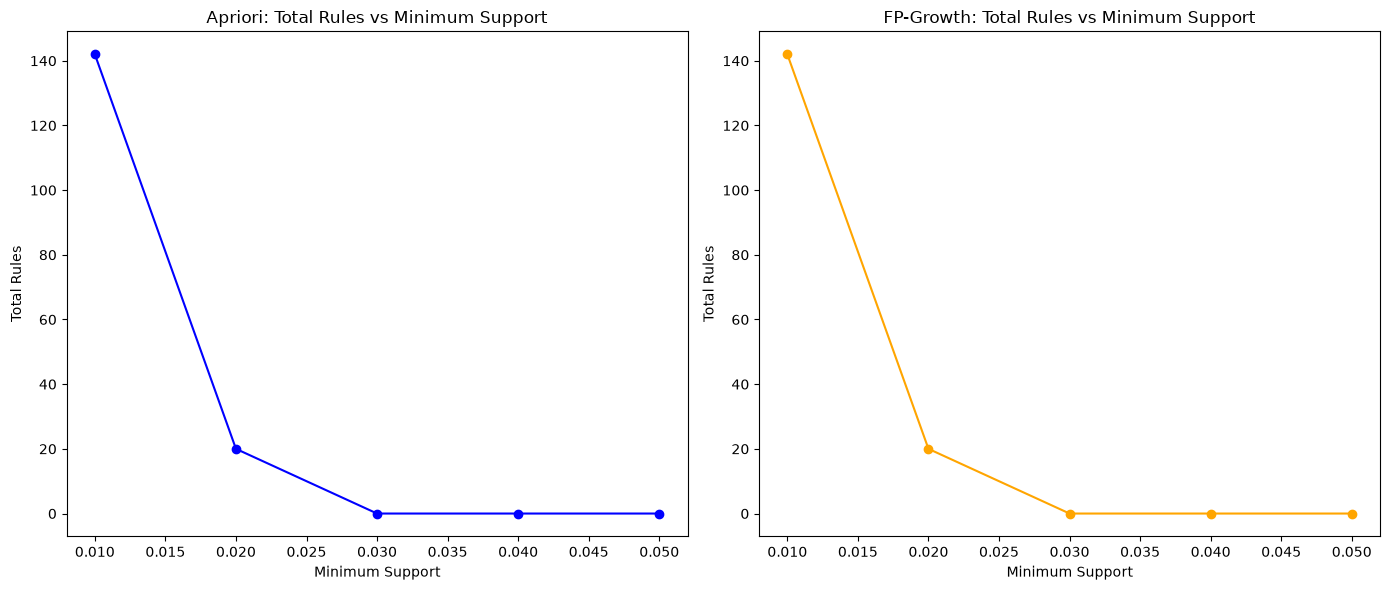

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
ax1.plot([0.01, 0.02, 0.03, 0.04, 0.05], n_rule_apriori, marker='o', color='blue')
ax1.set_title('Apriori: Total Rules vs Minimum Support')
ax1.set_xlabel('Minimum Support')
ax1.set_ylabel('Total Rules')

ax2.plot([0.01, 0.02, 0.03, 0.04, 0.05], n_rule_fpgrowth, marker='o', color='orange')
ax2.set_title('FP-Growth: Total Rules vs Minimum Support')
ax2.set_xlabel('Minimum Support')
ax2.set_ylabel('Total Rules')  
plt.tight_layout()

#### Avarage confidence vs min Support

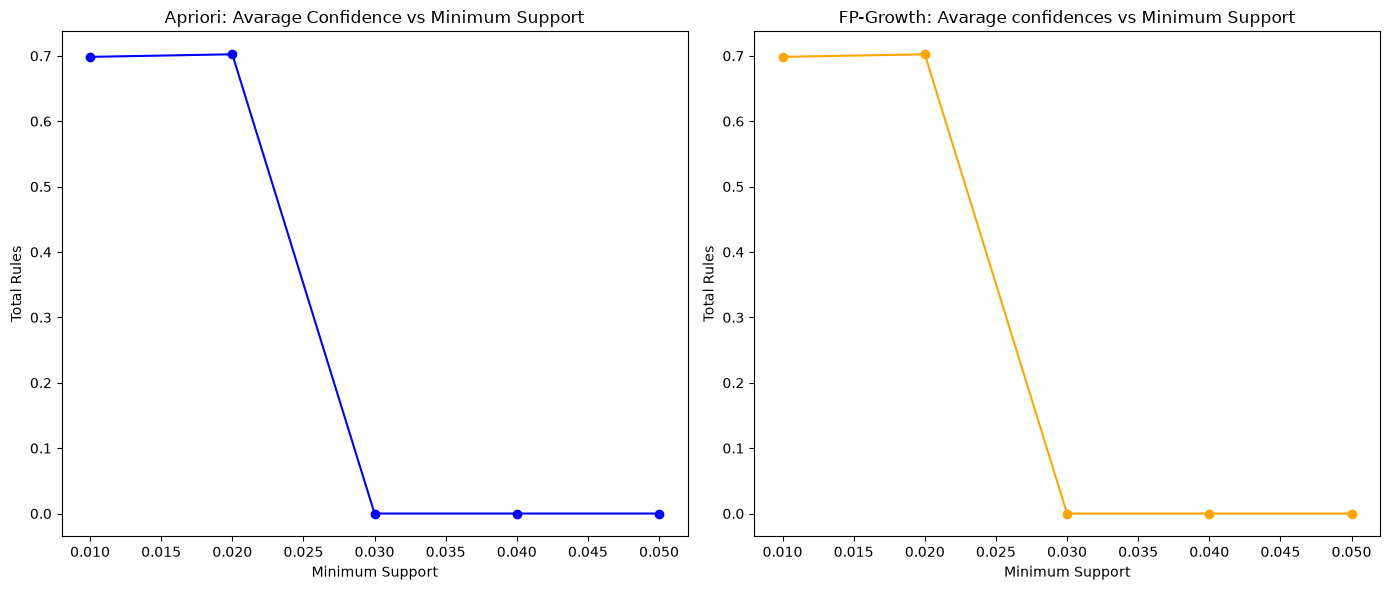

In [25]:
# versi confidence
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
ax1.plot([0.01, 0.02, 0.03, 0.04, 0.05], sum_confidence_apriori, marker='o', color='blue')
ax1.set_title('Apriori: Avarage Confidence vs Minimum Support')
ax1.set_xlabel('Minimum Support')
ax1.set_ylabel('Total Rules')                                                                                 

ax2.plot([0.01, 0.02, 0.03, 0.04, 0.05], sum_confidence_fpgrowth, marker='o', color='orange')
ax2.set_title('FP-Growth: Avarage confidences vs Minimum Support')
ax2.set_xlabel('Minimum Support')
ax2.set_ylabel('Total Rules')  
plt.tight_layout()

In [19]:
time_apriori

[21.84008168199989,
 0.5361253550001948,
 0.20438689999991766,
 0.09901051500014546,
 0.06872412699999586]

#### Time Execution vs min Support

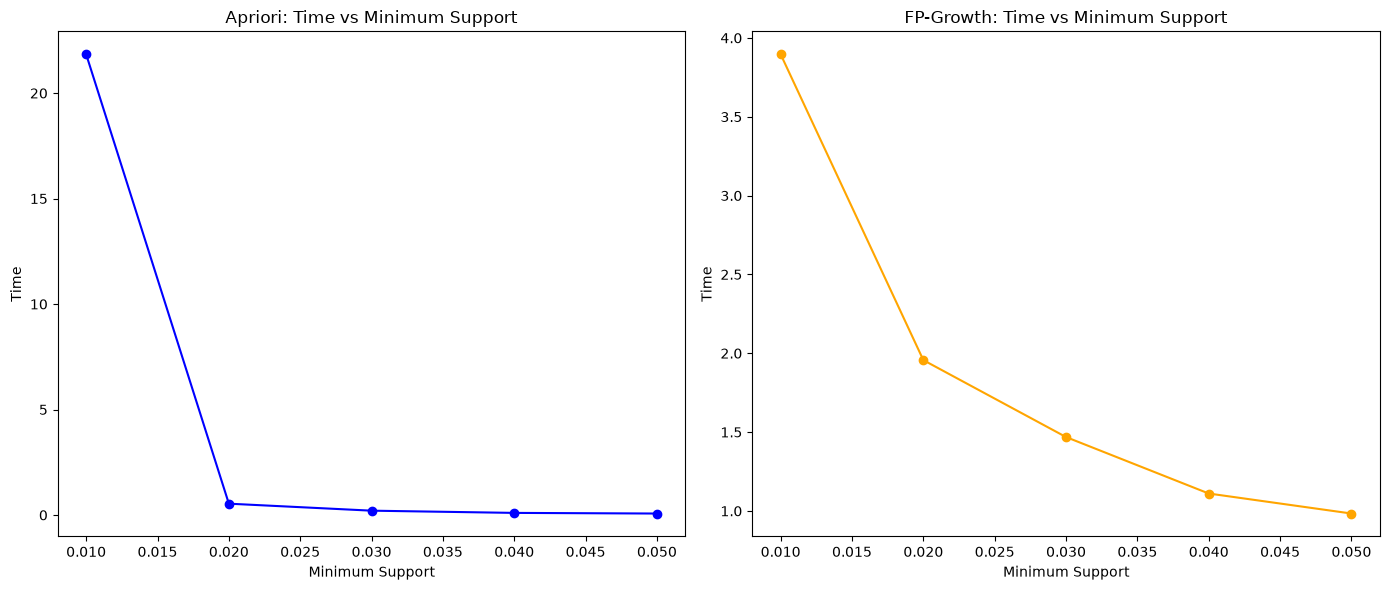

In [23]:
## perbandingan time 

import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
ax1.plot([0.01, 0.02, 0.03, 0.04, 0.05], time_apriori, marker='o', color='blue')
ax1.set_title('Apriori: Time vs Minimum Support')
ax1.set_xlabel('Minimum Support')
ax1.set_ylabel('Time')

ax2.plot([0.01, 0.02, 0.03, 0.04, 0.05], time_fpgrowth, marker='o', color='orange')
ax2.set_title('FP-Growth: Time vs Minimum Support')
ax2.set_xlabel('Minimum Support')
ax2.set_ylabel('Time')  
plt.tight_layout()

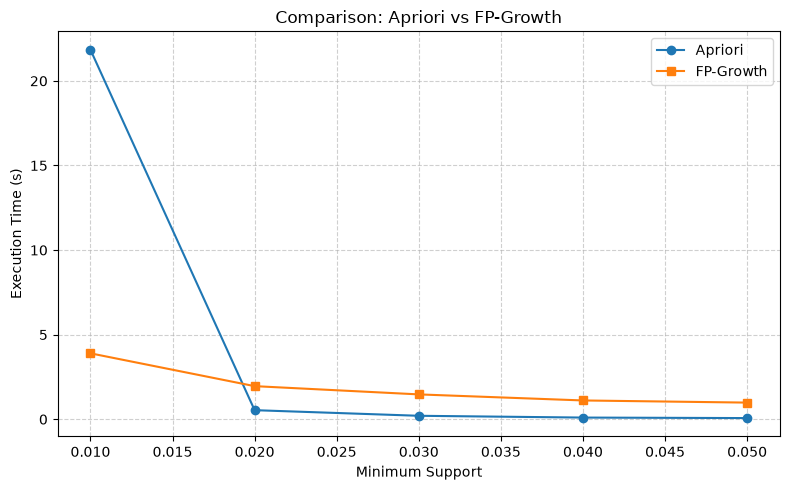

In [24]:
import matplotlib.pyplot as plt

# 1. Masukkan data
x = [0.01, 0.02, 0.03, 0.04, 0.05]
y1, label1 = time_apriori, 'Apriori'
y2, label2 = time_fpgrowth, 'FP-Growth'

# 2. Plot dua garis di satu axes
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, y1, marker='o', label=label1)
ax.plot(x, y2, marker='s', label=label2)

# 3. Label & layout
ax.set_title('Comparison: Apriori vs FP-Growth')
ax.set_xlabel('Minimum Support')
ax.set_ylabel('Execution Time (s)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Kesimpulan
Berdasarkan hasil eksperimen perbandingan algoritma Association Rule Mining (Apriori vs. FP-Growth) pada dataset Online Retail:
1. Kesetaraan Hasil dan Validitas Aturan:
   Apriori dan FP-Growth menghasilkan himpunan frequent itemsets dan aturan asosiasi yang 100% konsisten pada setiap pengujian parameter. Seluruh 20 aturan yang terbentuk pada min_support = 0.02 dan min_confidence = 0.60 memiliki nilai Lift > 1 (antara 6,30 hingga 24,03), yang membuktikan adanya keterkaitan nyata (korelasi positif) antar-produk

2. Trade-off Waktu Komputasi & Skalabilitas:
   FP-Growth terbukti jauh lebih terukur (scalable) pada threshold support rendah (min_support = 0,010), dengan waktu eksekusi 2,04 detik berbanding 29,57 detik pada Apriori (~14,5 kali lebih cepat). Sebaliknya, pada nilai support lebih tinggi (min_support >= 0,020), Apriori berjalan sedikit lebih cepat karena ketiadaan overhead konstruksi pohon FP-Tree.
Kesimpulan Akhir (Takeaway)

Nilai minimum support adalah parameter penentu utama dalam mengendalikan jumlah dan kualitas aturan asosiasi pada dataset transaksi ritel.
Untuk dataset transaksi berskala besar dengan variasi item tinggi (3.877 item unik), algoritma FP-Growth adalah pendekatan komputasi yang optimal untuk mengekstraksi pola transaksi pada ambang batas support rendah. Pola asosiasi yang terbentuk secara faktual menunjukkan ko-okurensi terkuat pada produk-produk yang merupakan varian desain dalam satu lini produk atau produk pelengkap dalam kategori utilitas yang sama.